# Ward hierarchical clustering

Use the same stratified 10,000-row sample from the shared 30,000 training rows
as notebook 05. Income is used only for stratified sampling and post-clustering
profiles. Ward linkage, cluster scores, and PCA use the full 33-feature
standardized/one-hot space; PCA is only a visualization. No test rows are read.

To compare cluster profiles at one common k, use a rule fixed before reviewing
the Ward scores: if any k ranks in the top three by Silhouette for both methods,
choose the smallest such k. If there is no overlap, choose the k minimizing the
sum of the two Silhouette ranks, breaking ties toward the smaller k.

## 1. Environment and shared training data

In [1]:
from pathlib import Path
import sys
import time
import platform

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import cut_tree, linkage
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from threadpoolctl import threadpool_info, threadpool_limits
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=1)

cwd = Path.cwd()
repo_root = cwd if (cwd / "src/preprocessing.py").exists() else cwd.parent
assert (repo_root / "src/unsupervised_common.py").exists(), (
    "Open from the repository root or notebooks/."
)
sys.path.insert(0, str(repo_root / "src"))
from unsupervised_common import (
    best_cluster_counts,
    cluster_profiles,
    clustering_sample,
    load_training_data,
    pca_projection,
    prepare_clustering,
)

results_dir = repo_root / "results"
results_dir.mkdir(exist_ok=True)
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")
data = load_training_data(repo_root)
print(f"Training rows: {len(data.X_train):,}; CV sample: {len(data.X_dev):,}; folds: {len(data.folds)}")

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1; numpy 2.5.4


Training rows: 172,459; CV sample: 30,000; folds: 5


## 2. Shared sample and preprocessing

Draw 10,000 rows by stratified sampling from the existing 30,000-row CV sample.
The resulting high-income rate should be 0.0861. Fit the same training-only
preprocessor as the classification notebooks on all 33 original features.

In [2]:
X_cluster, y_cluster = clustering_sample(data.X_dev, data.y_dev)
preprocessor, Z_cluster, preprocessing_seconds = prepare_clustering(X_cluster)
sample_info = pd.DataFrame([{
    "dev_rows": len(data.X_dev),
    "cluster_rows": len(X_cluster),
    "original_features": X_cluster.shape[1],
    "encoded_features": Z_cluster.shape[1],
    "dev_high_income_rate": data.y_dev.mean(),
    "sample_high_income_rate": y_cluster.mean(),
    "rate_tolerance": 1 / len(X_cluster),
    "preprocessing_seconds": preprocessing_seconds,
}])
sample_info.to_csv(results_dir / "ward_sample_info.csv", index=False)
display(sample_info)

,dev_rows,cluster_rows,original_features,encoded_features,dev_high_income_rate,sample_high_income_rate,rate_tolerance,preprocessing_seconds
0,30000,10000,33,436,0.086133,0.0861,0.0001,0.057055


## 3. Build one Ward tree and score k=2..10

`linkage(method="ward")` uses Euclidean distance in the full one-hot feature
space. The condensed pairwise-distance array for 10,000 rows is about 0.4 GB.
Build the hierarchy once, then cut that same tree at each k. All three scores
use all 10,000 rows and the full encoded space.

In [3]:
K_VALUES = list(range(2, 11))
kmeans_scores_path = results_dir / "kmeans_scores.csv"
kmeans_assignments_path = results_dir / "kmeans_assignments.csv"
kmeans_sample_info_path = results_dir / "kmeans_sample_info.csv"
assert kmeans_scores_path.exists() and kmeans_assignments_path.exists()
assert kmeans_sample_info_path.exists(), "Run notebook 05 before Ward comparison."

kmeans_scores = pd.read_csv(kmeans_scores_path)
kmeans_assignments = pd.read_csv(kmeans_assignments_path)
kmeans_sample_info = pd.read_csv(kmeans_sample_info_path)
assert kmeans_scores["k"].tolist() == K_VALUES
assert len(kmeans_assignments) == len(X_cluster)
assert np.array_equal(kmeans_assignments["row_index"].to_numpy(), X_cluster.index.to_numpy())
assert int(kmeans_sample_info.loc[0, "cluster_rows"]) == len(X_cluster)
assert int(kmeans_sample_info.loc[0, "original_features"]) == 33

linkage_started = time.perf_counter()
ward_tree = linkage(Z_cluster, method="ward", metric="euclidean")
linkage_seconds = time.perf_counter() - linkage_started
label_matrix = cut_tree(ward_tree, n_clusters=K_VALUES)

ward_rows = []
ward_profiles = []
ward_assignments = {}
for column, k in enumerate(K_VALUES):
    labels = label_matrix[:, column].astype(int)
    assert len(np.unique(labels)) == k
    metric_times = {}
    started = time.perf_counter()
    silhouette = silhouette_score(Z_cluster, labels)
    metric_times["Silhouette_seconds"] = time.perf_counter() - started
    started = time.perf_counter()
    calinski_harabasz = calinski_harabasz_score(Z_cluster, labels)
    metric_times["Calinski_Harabasz_seconds"] = time.perf_counter() - started
    started = time.perf_counter()
    davies_bouldin = davies_bouldin_score(Z_cluster, labels)
    metric_times["Davies_Bouldin_seconds"] = time.perf_counter() - started
    ward_rows.append({
        "k": k,
        "Silhouette": silhouette,
        "Calinski_Harabasz": calinski_harabasz,
        "Davies_Bouldin": davies_bouldin,
        "linkage_fit_seconds": linkage_seconds,
        "metrics_seconds": sum(metric_times.values()),
        **metric_times,
    })
    ward_assignments[k] = labels
    ward_profiles.append(cluster_profiles(labels, y_cluster, k))
    print(f"Completed Ward k={k}", flush=True)

ward_scores = pd.DataFrame(ward_rows)
ward_profile_table = pd.concat(ward_profiles, ignore_index=True)
ward_scores.to_csv(results_dir / "ward_scores.csv", index=False)
ward_best_k = best_cluster_counts(ward_scores)
ward_best_k.to_csv(results_dir / "ward_best_k.csv", index=False)
ward_profile_table.to_csv(results_dir / "ward_cluster_profiles.csv", index=False)
membership = pd.DataFrame({"row_index": X_cluster.index})
for k in K_VALUES:
    membership[f"ward_cluster_k_{k}"] = ward_assignments[k]
membership.to_csv(results_dir / "ward_assignments.csv", index=False)
display(ward_scores.round(6))
display(ward_best_k)

Completed Ward k=2


Completed Ward k=3


Completed Ward k=4


Completed Ward k=5


Completed Ward k=6


Completed Ward k=7


Completed Ward k=8


Completed Ward k=9


Completed Ward k=10


,k,Silhouette,Calinski_Harabasz,Davies_Bouldin,linkage_fit_seconds,metrics_seconds,Silhouette_seconds,Calinski_Harabasz_seconds,Davies_Bouldin_seconds
0,2,0.151180,1663.029614,2.104302,6.704432,1.025026,0.979638,0.026315,0.019072
1,3,0.165670,1210.953849,1.803383,6.704432,1.234812,1.211492,0.013470,0.009849
2,4,0.170299,1062.474760,1.440161,6.704432,0.751479,0.737999,0.006969,0.006512
3,5,0.174353,976.241697,1.588459,6.704432,0.726242,0.694768,0.024015,0.007460
4,6,0.176289,898.263990,1.343493,6.704432,0.724320,0.709068,0.008495,0.006757
5,7,0.124782,821.289305,1.936696,6.704432,0.629041,0.612218,0.009172,0.007651
6,8,0.074690,764.501557,2.172220,6.704432,0.687254,0.664700,0.013100,0.009454
7,9,0.070097,723.571544,2.275810,6.704432,0.550182,0.534020,0.008164,0.007998
8,10,0.070242,686.428160,2.205963,6.704432,0.538471,0.521568,0.008345,0.008557


,metric,direction,k,value
0,Silhouette,max,6,0.176289
1,Calinski_Harabasz,max,2,1663.029614
2,Davies_Bouldin,min,6,1.343493


## 4. Compare all scores and select common k by the pre-set rule

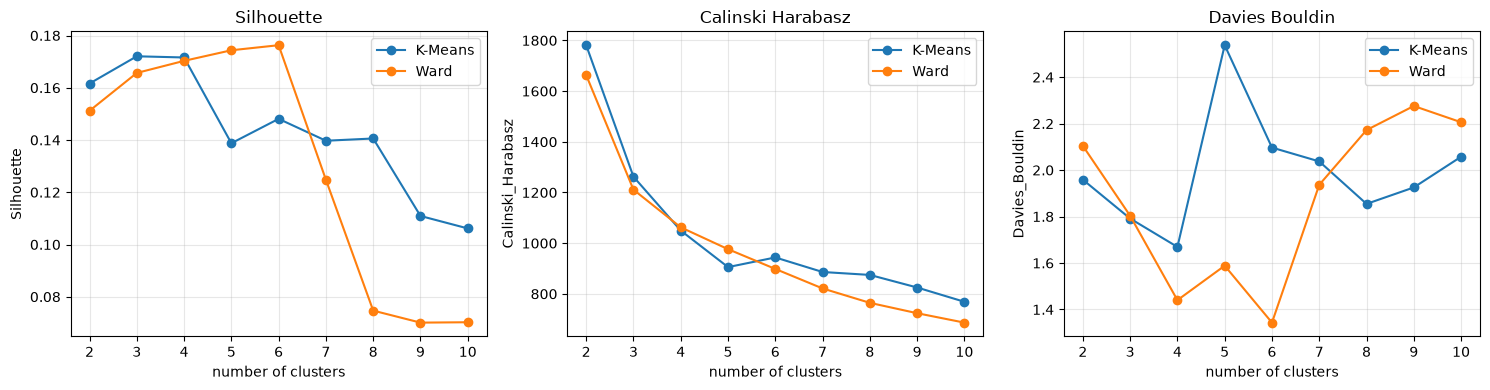

,method,metric,direction,k,value
0,K-Means,Silhouette,max,3,0.172045
1,K-Means,Calinski_Harabasz,max,2,1781.091840
2,K-Means,Davies_Bouldin,min,4,1.669318
3,Ward,Silhouette,max,6,0.176289
4,Ward,Calinski_Harabasz,max,2,1663.029614
5,Ward,Davies_Bouldin,min,6,1.343493


,common_k,selection_rule,kmeans_silhouette_rank,ward_silhouette_rank
0,4,smallest k ranked in the top three by Silhouet...,2,3


In [4]:
score_columns = ["Silhouette", "Calinski_Harabasz", "Davies_Bouldin"]
comparison = pd.concat([
    kmeans_scores.assign(method="K-Means"),
    ward_scores.assign(method="Ward"),
], ignore_index=True)
comparison.to_csv(results_dir / "clustering_score_comparison.csv", index=False)

best_by_method = pd.concat([
    best_cluster_counts(kmeans_scores).assign(method="K-Means"),
    ward_best_k.assign(method="Ward"),
], ignore_index=True)[["method", "metric", "direction", "k", "value"]]
best_by_method.to_csv(results_dir / "clustering_best_k_comparison.csv", index=False)

silhouette_ranks = {}
for method, frame in [("K-Means", kmeans_scores), ("Ward", ward_scores)]:
    ordered = frame.sort_values(["Silhouette", "k"], ascending=[False, True])
    silhouette_ranks[method] = dict(zip(ordered["k"].astype(int), range(1, len(ordered) + 1)))
eligible = [k for k in K_VALUES
            if silhouette_ranks["K-Means"][k] <= 3 and silhouette_ranks["Ward"][k] <= 3]
if eligible:
    COMMON_K = min(eligible)
    common_k_reason = "smallest k ranked in the top three by Silhouette for both methods"
else:
    COMMON_K = min(K_VALUES, key=lambda k: (
        silhouette_ranks["K-Means"][k] + silhouette_ranks["Ward"][k], k
    ))
    common_k_reason = "no top-three overlap; smallest k minimizing the sum of Silhouette ranks"

common_k_record = pd.DataFrame([{
    "common_k": COMMON_K,
    "selection_rule": common_k_reason,
    "kmeans_silhouette_rank": silhouette_ranks["K-Means"][COMMON_K],
    "ward_silhouette_rank": silhouette_ranks["Ward"][COMMON_K],
}])
common_k_record.to_csv(results_dir / "clustering_common_k.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, score_columns):
    for method, group in comparison.groupby("method"):
        ax.plot(group["k"], group[metric], marker="o", label=method)
    ax.set(title=metric.replace("_", " "), xlabel="number of clusters", ylabel=metric)
    ax.set_xticks(K_VALUES)
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

display(best_by_method)
display(common_k_record)

## 5. High-income rates at the shared common k

In [5]:
kmeans_profiles = pd.read_csv(results_dir / "kmeans_cluster_profiles.csv")
common_profiles = pd.concat([
    kmeans_profiles.loc[kmeans_profiles["k"] == COMMON_K].assign(method="K-Means"),
    ward_profile_table.loc[ward_profile_table["k"] == COMMON_K].assign(method="Ward"),
], ignore_index=True)[["method", "k", "cluster", "count", "high_income_rate"]]
common_profiles.to_csv(results_dir / "clustering_common_k_profiles.csv", index=False)
display(common_profiles.sort_values(["method", "cluster"]).round(6))

,method,k,cluster,count,high_income_rate
0,K-Means,4,0,6095,0.123544
1,K-Means,4,1,685,0.045255
2,K-Means,4,2,3199,0.018443
3,K-Means,4,3,21,0.857143
4,Ward,4,0,6144,0.111654
5,Ward,4,1,3573,0.021271
6,Ward,4,2,262,0.309160
7,Ward,4,3,21,0.857143


## 6. PCA view of the common-k assignments

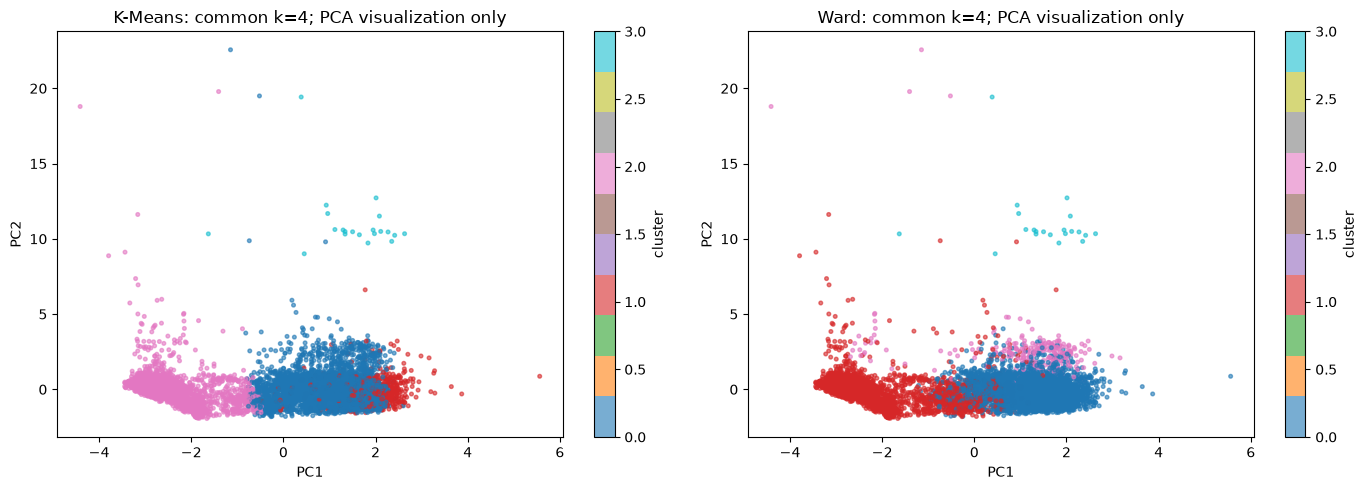

In [6]:
coordinates, pca = pca_projection(Z_cluster)
pd.DataFrame({
    "component": [1, 2],
    "explained_variance_ratio": pca.explained_variance_ratio_,
}).to_csv(results_dir / "ward_pca_variance.csv", index=False)
kmeans_common_labels = kmeans_assignments[f"cluster_k_{COMMON_K}"].to_numpy()
ward_common_labels = ward_assignments[COMMON_K]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labels, method in zip(
    axes, [kmeans_common_labels, ward_common_labels], ["K-Means", "Ward"]
):
    points = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=labels,
                        cmap="tab10", s=7, alpha=0.6)
    fig.colorbar(points, ax=ax, label="cluster")
    ax.set(title=f"{method}: common k={COMMON_K}; PCA visualization only",
           xlabel="PC1", ylabel="PC2")
fig.tight_layout()
plt.show()

## 7. Final checks and execution time

In [7]:
assert len(data.X_dev) == 30_000 and len(data.folds) == 5
assert X_cluster.shape == (10_000, 33)
assert round(float(y_cluster.mean()), 4) == 0.0861
assert set(X_cluster.columns) == set(data.X_dev.columns)
assert ward_scores["k"].tolist() == K_VALUES and len(ward_scores) == 9
assert np.isfinite(ward_scores[score_columns]).all().all()
assert len(ward_profile_table) == sum(K_VALUES)
assert ward_profile_table.groupby("k")["count"].sum().eq(10_000).all()
assert all(len(np.unique(ward_assignments[k])) == k for k in K_VALUES)
assert common_profiles["method"].nunique() == 2
assert common_profiles.groupby("method")["count"].sum().eq(10_000).all()
assert all(item["num_threads"] == 1 for item in threadpool_info())
total_seconds = time.perf_counter() - experiment_started
pd.DataFrame([{
    "total_seconds": total_seconds,
    "ward_linkage_seconds": linkage_seconds,
    "python": platform.python_version(),
    "sklearn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "native_threads": 1,
}]).to_csv(results_dir / "ward_execution.csv", index=False)
print("Final checks passed.")
print(f"Ward linkage fit: {linkage_seconds:.2f} seconds")
print(f"Selected common k: {COMMON_K} ({common_k_reason})")
print(f"Total execution time: {total_seconds:.2f} seconds")

Final checks passed.
Ward linkage fit: 6.70 seconds
Selected common k: 4 (smallest k ranked in the top three by Silhouette for both methods)
Total execution time: 18.45 seconds
